# TP 2 — Deep Learning pour le NLP

**Cours NLP et Transformers — CY Tech**

Même tâche que le TP 1 : retrouver lequel des 5 personnages dit la réplique.

1. nettoyer
2. représenter le texte
3. comparer ML et réseaux
4. évaluer sur le test (une seule fois)


## 0. Environnement


In [1]:
import re
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42  # pour retrouver le même découpage
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

print("torch", torch.__version__)


torch 2.8.0


## 1. Nettoyage

Même parser que le TP 1. Ensuite on met en minuscules et on ne garde que les mots.


In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
urllib.request.urlretrieve(URL, "input.txt")
texte = open("input.txt", encoding="utf-8").read()


def parser_repliques(txt):
    # un bloc = une ligne vide, puis "NOM:" puis la réplique
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


def nettoyer(phrase):
    # minuscules, on jette la ponctuation. l'apostrophe reste (don't)
    mots = re.findall(r"[a-z]+(?:'[a-z]+)?", phrase.lower())
    return " ".join(mots)


df = parser_repliques(texte)
df["n_mots"] = df["replique"].str.split().str.len()

N_LOCUTEURS, MIN_MOTS = 5, 5  # les 5 plus bavards, répliques pas trop courtes
top = df["locuteur"].value_counts().head(N_LOCUTEURS).index
donnees = df[df["locuteur"].isin(top)].query("n_mots >= @MIN_MOTS").copy()
donnees["propre"] = donnees["replique"].map(nettoyer)
donnees = donnees[donnees["propre"].str.len() > 0].reset_index(drop=True)

print(donnees["locuteur"].value_counts())
print(f"{len(donnees)} répliques après nettoyage")
print("exemple :", donnees["propre"].iloc[0])


locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64
761 répliques après nettoyage
exemple : what work's my countrymen in hand where go you with bats and clubs the matter speak i pray you


`Love` et `love` feraient deux mots différents. Le nom du personnage ne change pas, c'est l'étiquette.


## Découpage

20 % de test, puis 20 % du reste en validation. Le test ne sert pas à choisir les réglages.


In [3]:
# stratify : même proportion de chaque perso dans chaque partie
X_reste, X_test, y_reste, y_test = train_test_split(
    donnees["propre"], donnees["locuteur"],
    test_size=0.20, stratify=donnees["locuteur"], random_state=RANDOM_STATE,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_reste, y_reste, test_size=0.20, stratify=y_reste, random_state=RANDOM_STATE,
)
classes = sorted(y_train.unique())
print(f"train {len(X_train)}   val {len(X_val)}   test {len(X_test)}")
print("classes :", classes)


train 486   val 122   test 153
classes : ['DUKE VINCENTIO', 'GLOUCESTER', 'MENENIUS', 'PETRUCHIO', 'ROMEO']


La validation sert à régler. Le test, on ne le regarde qu'à la fin.


## 2. Représentation

- TF–IDF pour Naive Bayes et la logistique (pas d'ordre des mots).
- Une suite d'entiers pour les réseaux. 0 = padding, 1 = mot inconnu.


In [4]:
# (1, 2) = mots seuls et paires de mots. min_df=2 : on ignore un mot vu une seule fois
vectoriseur = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
Xtr_tf = vectoriseur.fit_transform(X_train)  # fit sur le train seulement
Xva_tf = vectoriseur.transform(X_val)
Xte_tf = vectoriseur.transform(X_test)
print("TF–IDF :", Xtr_tf.shape)

MAX_LEN, MIN_DF = 40, 2  # on coupe à 40 mots ; mot gardé s'il apparaît au moins 2 fois
compte = {}
for phrase in X_train:
    for mot in phrase.split():
        compte[mot] = compte.get(mot, 0) + 1
vocab = [m for m, n in sorted(compte.items()) if n >= MIN_DF]
stoi = {m: i + 2 for i, m in enumerate(vocab)}  # 0 et 1 sont déjà pris


def encoder(phrases):
    lots = []
    for phrase in phrases:
        ids = [stoi.get(m, 1) for m in phrase.split()][:MAX_LEN]  # 1 si le mot n'est pas dans le train
        lots.append(ids or [1])
    return lots


def vers_tenseur(lots):
    # on complète avec des 0 pour que toutes les lignes aient la même longueur
    T = min(MAX_LEN, max(len(x) for x in lots))
    x = torch.zeros(len(lots), T, dtype=torch.long)
    for i, ids in enumerate(lots):
        ids = ids[:T]
        x[i, :len(ids)] = torch.tensor(ids)
    return x


tr_ids, va_ids, te_ids = encoder(X_train), encoder(X_val), encoder(X_test)
print(f"vocabulaire {len(stoi)} mots, plus pad et unk")
print("une réplique :", tr_ids[0][:12])


TF–IDF : (486, 2803)
vocabulaire 1333 mots, plus pad et unk
une réplique : [75, 852, 442, 578, 1, 540, 407, 777, 581, 1000, 41, 578]


Le vocabulaire est fait sur le train. Un mot du test qu'on n'a jamais vu devient 1.


## 3. Modèles

| Modèle | Entrée |
|---|---|
| Baseline, Naive Bayes, logistique | TF–IDF |
| Moyenne des embeddings + MLP | les mots, sans l'ordre |
| GRU dans les deux sens | la suite des mots |

`class_weight="balanced"` : un perso rare compte autant qu'un perso fréquent.


In [5]:
def f1_macro(y_vrai, y_pred):
    # moyenne des F1 de chaque perso, pour ne pas avantager le plus bavard
    return f1_score(y_vrai, y_pred, average="macro", labels=classes, zero_division=0)


resultats_val = {}
meilleur_C = None
meilleur_f1 = -1
# C petit = plus de régularisation. on garde celui qui gagne sur la validation
for C in (0.1, 1.0, 10.0):
    clf = LogisticRegression(C=C, max_iter=500, class_weight="balanced", random_state=RANDOM_STATE)
    clf.fit(Xtr_tf, y_train)
    score = f1_macro(y_val, clf.predict(Xva_tf))
    print(f"logistique C={C:<4}  F1 val {score:.3f}")
    if score > meilleur_f1:
        meilleur_f1, meilleur_C = score, C

modeles_ml = {
    "majoritaire": DummyClassifier(strategy="most_frequent"),  # toujours le perso le plus fréquent
    "naive bayes": MultinomialNB(),
    "logistique": LogisticRegression(C=meilleur_C, max_iter=500, class_weight="balanced", random_state=RANDOM_STATE),
}
for nom, clf in modeles_ml.items():
    clf.fit(Xtr_tf, y_train)
    resultats_val[nom] = f1_macro(y_val, clf.predict(Xva_tf))
print("retenu : C =", meilleur_C)


logistique C=0.1   F1 val 0.558
logistique C=1.0   F1 val 0.596
logistique C=10.0  F1 val 0.586
retenu : C = 1.0


In [6]:
code_y = {nom: i for i, nom in enumerate(classes)}


def y_tensor(serie):
    return torch.tensor([code_y[v] for v in serie], dtype=torch.long)


# poids plus fort sur les classes rares, sinon le réseau ne prédit que la plus grosse
poids = compute_class_weight("balanced", classes=np.arange(len(classes)), y=[code_y[v] for v in y_train])
poids = torch.tensor(poids, dtype=torch.float32)


class MoyenneMLP(nn.Module):
    def __init__(self, n_vocab, n_classes, dim=64):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, dim, padding_idx=0)  # dim = taille du vecteur d'un mot
        self.fc1 = nn.Linear(dim, dim)
        self.fc2 = nn.Linear(dim, n_classes)
        self.drop = nn.Dropout(0.15)  # on éteint 15 % des neurones à l'entraînement

    def forward(self, x):
        masque = (x != 0).unsqueeze(-1).float()  # les 0 de padding ne comptent pas
        moyenne = (self.emb(x) * masque).sum(1) / masque.sum(1).clamp(min=1)
        return self.fc2(self.drop(torch.relu(self.fc1(moyenne))))


class BiGRU(nn.Module):
    def __init__(self, n_vocab, n_classes, dim=64):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, dim, padding_idx=0)
        self.gru = nn.GRU(dim, dim, batch_first=True, bidirectional=True)  # lecture gauche-droite et droite-gauche
        self.fc = nn.Linear(2 * dim, n_classes)
        self.drop = nn.Dropout(0.15)

    def forward(self, x):
        longueurs = (x != 0).sum(1).clamp(min=1).cpu()
        emb = self.drop(self.emb(x))
        # pack : le GRU s'arrête au vrai dernier mot, il ne lit pas les 0
        paquet = pack_padded_sequence(emb, longueurs, batch_first=True, enforce_sorted=False)
        _, h = self.gru(paquet)
        concat = torch.cat([h[0], h[1]], dim=-1)  # les deux sens
        return self.fc(self.drop(concat))


def lots(ids, labels, batch=64):
    ordre = np.random.permutation(len(ids))
    for debut in range(0, len(ids), batch):
        idx = ordre[debut:debut + batch]
        yield vers_tenseur([ids[i] for i in idx]), labels[idx]


def entrainer(fabrique, graine, epoques=40, patience=8):
    # epoques = max. patience = on s'arrête si la val ne s'améliore plus pendant 8 tours
    torch.manual_seed(graine)
    np.random.seed(graine)
    modele = fabrique()
    opt = torch.optim.AdamW(modele.parameters(), lr=2e-3, weight_decay=1e-4)  # lr = taille du pas
    loss_fn = nn.CrossEntropyLoss(weight=poids)
    ytr, yva = y_tensor(y_train), y_tensor(y_val)
    xva = vers_tenseur(va_ids)
    meilleur, attente, etat = -1.0, 0, None
    courbe = []
    for ep in range(epoques):
        modele.train()
        for xb, yb in lots(tr_ids, ytr):
            opt.zero_grad()
            loss_fn(modele(xb), yb).backward()
            opt.step()
        modele.eval()
        with torch.no_grad():
            pred = modele(xva).argmax(1).numpy()
        score = f1_macro(y_val, [classes[i] for i in pred])
        courbe.append(score)
        if score > meilleur + 1e-4:
            meilleur, attente = score, 0
            etat = {k: v.detach().clone() for k, v in modele.state_dict().items()}
        else:
            attente += 1
            if attente >= patience:
                break
    modele.load_state_dict(etat)  # on revient aux poids de la meilleure époque
    return modele, meilleur, courbe


def fabriquer(classe):
    return lambda: classe(len(stoi) + 2, len(classes))


courbes = {}
meilleurs_etats = {}
for nom, classe in (("moyenne + MLP", MoyenneMLP), ("BiGRU", BiGRU)):
    scores = []
    meilleur_score, meilleur_etat = -1.0, None
    for graine in (0, 1, 2):  # 3 initialisations, le résultat bouge un peu
        t0 = time.perf_counter()
        modele, score, courbe = entrainer(fabriquer(classe), graine)
        scores.append(score)
        if graine == 0:
            courbes[nom] = courbe
        if score > meilleur_score:
            meilleur_score = score
            meilleur_etat = {k: v.detach().clone() for k, v in modele.state_dict().items()}
        print(f"{nom:<16} graine {graine}  F1 val {score:.3f}  {len(courbe)} époques  ({time.perf_counter() - t0:.0f} s)")
    torch.save(meilleur_etat, f"/tmp/{nom.split()[0]}.pt")
    meilleurs_etats[nom] = meilleur_score
    resultats_val[nom] = (float(np.mean(scores)), float(np.std(scores)))

print("\nparamètres moyenne+MLP", sum(p.numel() for p in MoyenneMLP(len(stoi) + 2, len(classes)).parameters()))
print("paramètres BiGRU     ", sum(p.numel() for p in BiGRU(len(stoi) + 2, len(classes)).parameters()))
print("paramètres logistique", int(np.prod(modeles_ml['logistique'].coef_.shape)))


moyenne + MLP    graine 0  F1 val 0.536  40 époques  (1 s)
moyenne + MLP    graine 1  F1 val 0.476  40 époques  (1 s)
moyenne + MLP    graine 2  F1 val 0.495  40 époques  (1 s)
BiGRU            graine 0  F1 val 0.441  33 époques  (6 s)
BiGRU            graine 1  F1 val 0.364  26 époques  (5 s)
BiGRU            graine 2  F1 val 0.411  26 époques  (5 s)

paramètres moyenne+MLP 89925
paramètres BiGRU      136005
paramètres logistique 14015


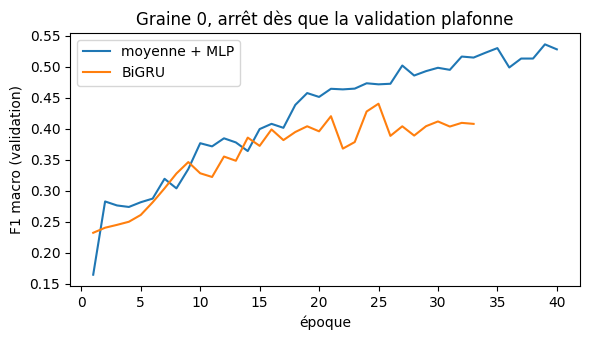

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for nom, courbe in courbes.items():
    ax.plot(range(1, len(courbe) + 1), courbe, label=nom)
ax.set_xlabel("époque")
ax.set_ylabel("F1 macro (validation)")
ax.legend()
ax.set_title("Graine 0")
plt.tight_layout()
plt.show()


Dès que la courbe de validation plafonne, on s'arrête. Continuer collerait au train sans gagner sur des phrases nouvelles.


## 4. Évaluation

On garde, pour chaque réseau, la graine qui a le meilleur F1 en validation. Tout le monde est noté sur le même test, en F1 macro.


In [8]:
def recharger(classe, fichier):
    modele = classe(len(stoi) + 2, len(classes))
    modele.load_state_dict(torch.load(fichier, weights_only=True))
    modele.eval()
    return modele


reseaux = {
    "moyenne + MLP": recharger(MoyenneMLP, "/tmp/moyenne.pt"),
    "BiGRU": recharger(BiGRU, "/tmp/BiGRU.pt"),
}

lignes = []
preds = {}
for nom, clf in modeles_ml.items():
    pred = clf.predict(Xte_tf)
    preds[nom] = pred
    lignes.append({"modèle": nom, "F1 val": resultats_val[nom], "F1 test": f1_macro(y_test, pred)})

xte = vers_tenseur(te_ids)
for nom, modele in reseaux.items():
    with torch.no_grad():
        pred_i = modele(xte).argmax(1).numpy()
    pred = [classes[i] for i in pred_i]
    preds[nom] = pred
    moy, ecart = resultats_val[nom]
    lignes.append({"modèle": nom, "F1 val": f"{moy:.3f} ± {ecart:.3f}", "F1 test": f1_macro(y_test, pred)})

tableau = pd.DataFrame(lignes).set_index("modèle")
print(tableau.round(3).to_string())
print()
gagnant = max(preds, key=lambda n: f1_macro(y_test, preds[n]))
print("meilleur sur le test :", gagnant)
print(classification_report(y_test, preds[gagnant], zero_division=0))


                      F1 val  F1 test
modèle                               
majoritaire         0.081046    0.083
naive bayes         0.438543    0.500
logistique          0.596421    0.599
moyenne + MLP  0.502 ± 0.025    0.504
BiGRU          0.405 ± 0.031    0.402

meilleur sur le test : logistique
                precision    recall  f1-score   support

DUKE VINCENTIO       0.61      0.61      0.61        33
    GLOUCESTER       0.62      0.50      0.56        40
      MENENIUS       0.48      0.64      0.55        25
     PETRUCHIO       0.76      0.59      0.67        27
         ROMEO       0.56      0.68      0.61        28

      accuracy                           0.59       153
     macro avg       0.61      0.60      0.60       153
  weighted avg       0.61      0.59      0.60       153



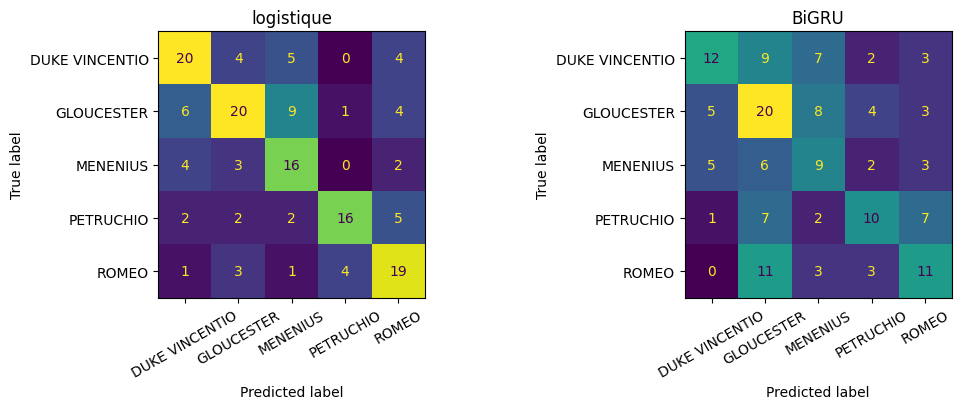

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, nom in zip(axes, ("logistique", gagnant if gagnant != "logistique" else "BiGRU")):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, preds[nom], labels=classes), display_labels=classes,
    ).plot(ax=ax, colorbar=False, xticks_rotation=30)
    ax.set_title(nom)
plt.tight_layout()
plt.show()


In [10]:
# lignes où la logistique et le réseau ne disent pas la même chose
autre = "BiGRU" if gagnant == "logistique" else gagnant
desaccord = np.array(preds["logistique"]) != np.array(preds[autre])
print(f"désaccord sur {desaccord.mean():.0%} du test")
apercu = pd.DataFrame({
    "réplique": X_test.to_numpy()[desaccord][:6],
    "vrai": y_test.to_numpy()[desaccord][:6],
    "logistique": np.array(preds["logistique"])[desaccord][:6],
    autre: np.array(preds[autre])[desaccord][:6],
})
print(apercu.to_string(index=False))


désaccord sur 54% du test
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              réplique           vrai     logistique          BiGRU
                                                                                                                                                                                                                                                                          

## Bilan

Sur le test : logistique 0,60, moyenne + MLP 0,50, BiGRU 0,40. La baseline majoritaire est à 0,08.

Le BiGRU a beaucoup plus de paramètres (136 000 contre 14 000) et son score bouge selon la graine. Ici le réseau ne bat pas le TF–IDF : les répliques sont courtes, et l'ordre des mots aide peu.
